# SImulations

In this notebook we simulate experiments to prove the efficacy of the Softmin Energy minimization method over other established global optimization methods.
The Softmin energy is defined as 
$$
    J_\beta(\mathbf{x}) = \sum_{i=1}^n \frac{e^{-\beta f (x_i)}f(x_i)}{\sum_{j=1}^n e^{-\beta f(x_j)}}
$$
with $\beta>0$, $\mathbf{x} = (x_1,\dots,x_n)$.

## Imports and utility functions

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle as pkl

from tqdm import tqdm
from swarm_particle_optimization import *
import multiprocessing as mp

plt.rcParams['font.size'] = 15
#uncomment to double the fontsize in plots

N_CPU = mp.cpu_count()

## Exit time from the maximizing regime

### Plot

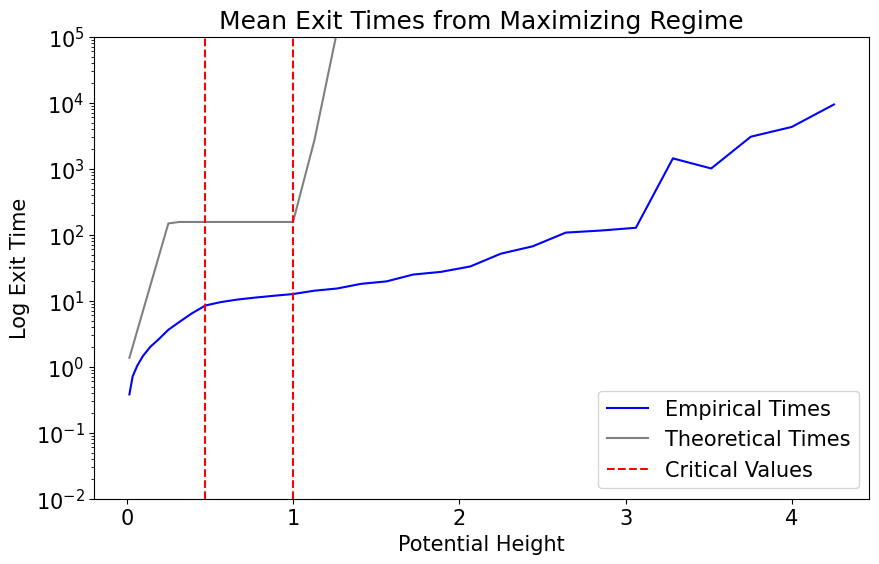

In [ ]:
noise = 0.05
beta = 2
mean_exit_times, theory_bounds, x = [], [], []
q1_exit_times, q3_exit_times, std_exit_times = [], [], []

critical_values= []
for delta in np.arange(0.25,4.25,0.125):
    kwargs = one_dimensional_double_well(delta)
    f_star = kwargs['f_vec']([kwargs['critical_points'][1]]) - kwargs['f_vec']([kwargs['critical_points'][0]])
    if delta.is_integer(): delta = int(delta)
    string = f"softmin_static_double_well_init0_{delta}_{noise}".replace('.','p')+".pkl"
    with open(f"results/{string}", "rb") as f:
        exit_times = pkl.load(f)
    if f_star > 1/beta and 100/(2*99*beta) > (f_star-1/beta)**2:
        if len(critical_values) == 0:
            critical_values.append(x[-1])
    elif f_star > 1/beta and 100/(2*99*beta) <= (f_star-1/beta)**2:
        if len(critical_values) <= 1:
            critical_values.append(x[-1])
    x.append(f_star)


    mean_exit_times.append(np.mean(exit_times))
    delta_v_eff = max(min(f_star,100/(2*99*beta)),(max(f_star-1/beta,0))**2)
    theory_bounds.append(np.exp(delta_v_eff/noise))

    std_exit_times.append(np.std(exit_times))
    q1_exit_times.append(np.percentile(exit_times, 25))
    q3_exit_times.append(np.percentile(exit_times, 75))

def get_asymmetric_errorbars(mean, q1, q3):
    lower = np.array(mean) - np.array(q1)
    upper = np.array(q3) - np.array(mean)
    return [np.maximum(lower, 0), np.maximum(upper, 0)]


fig, ax = plt.subplots(figsize=(10, 6))
err_exit_times = get_asymmetric_errorbars(mean_exit_times, q1_exit_times, q3_exit_times)
ax.plot(x, mean_exit_times, label='Empirical Times', color='blue')y')
ax.vlines(critical_values, ymin=1e-2, ymax=1e5, colors='red', linestyles='dashed', label='Critical Values')
ax.set_yscale('log')
ax.set_ylim(1e-2, 1e5)
ax.set_xlabel('Potential Height')
ax.set_ylabel('Log Exit Time')
ax.set_title('Mean Exit Times from Maximizing Regime')
ax.legend()

## 1 Dimensional Double Well Potential

### Plots

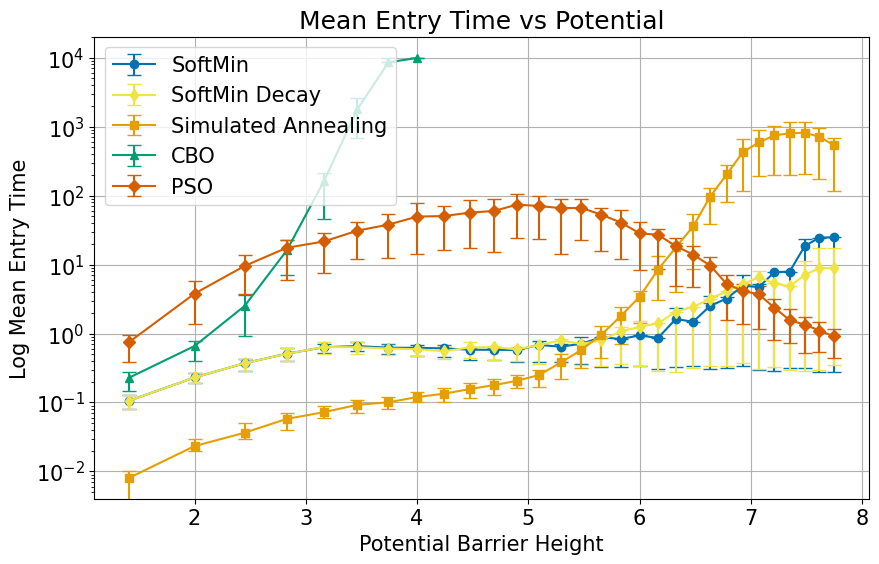

In [43]:
mean_entry_times_softmin, mean_entry_times_softmin_decay, mean_entry_times_simulated_annealing, mean_entry_times_cbo, mean_entry_times_pso = [], [], [], [], []
q1_softmin, q3_softmin = [], []
q1_softmin_decay, q3_softmin_decay = [], []
q1_simulated_annealing, q3_simulated_annealing = [], []
q1_cbo, q3_cbo = [], []
q1_pso, q3_pso = [], []

x = []
for delta in range(1, 31):
    kwargs = one_dimensional_double_well(delta)
    x.append(kwargs['critical_points'][2] - kwargs['critical_points'][0])
    with open('results/'+'softmin_double_well'+f'_{delta}.pkl', "rb") as f:
        entry_times_softmin = pkl.load(f)
    with open('results/'+'softmin_decay_highermaxsteps_double_well'+f'_{delta}.pkl', "rb") as f:
        entry_times_softmin_decay = pkl.load(f)
    with open('results/'+'sa_double_well'+f'_{delta}.pkl', "rb") as f:
        entry_times_simulated_annealing = pkl.load(f)
    with open('results/'+'cbo_double_well'+f'_{delta}.pkl', "rb") as f:
        entry_times_cbo = pkl.load(f)
    with open('results/'+'pso_double_well'+f'_{delta}.pkl', "rb") as f:
        entry_times_pso = pkl.load(f)

    mean_entry_times_softmin.append(np.mean(entry_times_softmin))
    mean_entry_times_softmin_decay.append(np.mean(entry_times_softmin_decay))
    mean_entry_times_simulated_annealing.append(np.mean(entry_times_simulated_annealing))
    mean_entry_times_cbo.append(np.mean(entry_times_cbo))
    mean_entry_times_pso.append(np.mean(entry_times_pso))

    q1_softmin.append(np.percentile(entry_times_softmin, 25))
    q3_softmin.append(np.percentile(entry_times_softmin, 75))
    q1_softmin_decay.append(np.percentile(entry_times_softmin_decay, 25))
    q3_softmin_decay.append(np.percentile(entry_times_softmin_decay, 75))
    q1_simulated_annealing.append(np.percentile(entry_times_simulated_annealing, 25))
    q3_simulated_annealing.append(np.percentile(entry_times_simulated_annealing, 75))
    q1_cbo.append(np.percentile(entry_times_cbo, 25))
    q3_cbo.append(np.percentile(entry_times_cbo, 75))
    q1_pso.append(np.percentile(entry_times_pso, 25))
    q3_pso.append(np.percentile(entry_times_pso, 75))

def get_asymmetric_errorbars(mean, q1, q3):
    lower = np.array(mean) - np.array(q1)
    upper = np.array(q3) - np.array(mean)
    return [np.maximum(0,lower), np.maximum(0,upper)]

err_softmin = get_asymmetric_errorbars(mean_entry_times_softmin, q1_softmin, q3_softmin)
err_softmin_decay = get_asymmetric_errorbars(mean_entry_times_softmin_decay, q1_softmin_decay, q3_softmin_decay)
err_simulated_annealing = get_asymmetric_errorbars(mean_entry_times_simulated_annealing, q1_simulated_annealing, q3_simulated_annealing)
err_cbo = get_asymmetric_errorbars(mean_entry_times_cbo, q1_cbo, q3_cbo)
err_pso = get_asymmetric_errorbars(mean_entry_times_pso, q1_pso, q3_pso)

x= np.array(x)
mean_entry_times_softmin = np.array(mean_entry_times_softmin)
mean_entry_times_softmin_decay = np.array(mean_entry_times_softmin_decay)
mean_entry_times_simulated_annealing = np.array(mean_entry_times_simulated_annealing)
mean_entry_times_cbo = np.array(mean_entry_times_cbo)
mean_entry_times_pso = np.array(mean_entry_times_pso)
err_softmin = np.array(err_softmin)
err_softmin_decay = np.array(err_softmin_decay)
err_simulated_annealing = np.array(err_simulated_annealing)
err_cbo = np.array(err_cbo)
err_pso = np.array(err_pso)

fig, ax = plt.subplots(figsize=(10, 6))
ax.errorbar(x, mean_entry_times_softmin, yerr=err_softmin, label='SoftMin',
            marker='o', color='#0072B2', capsize=5, linestyle='-')
ax.errorbar(x, mean_entry_times_softmin_decay, yerr=err_softmin_decay, label='SoftMin Decay',
            marker='d', color='#F0E442', capsize=5, linestyle='-')
ax.errorbar(x, mean_entry_times_simulated_annealing, yerr=err_simulated_annealing, label='Simulated Annealing',
            marker='s', color='#E69F00', capsize=5, linestyle='-')
ax.errorbar(x[np.where(mean_entry_times_cbo<1e4)], mean_entry_times_cbo[np.where(mean_entry_times_cbo<1e4)], yerr=np.squeeze(err_cbo[:,np.where(mean_entry_times_cbo<1e4)],axis=1), label='CBO',
            marker='^', color='#009E73', capsize=5, linestyle='-')
ax.errorbar(x, mean_entry_times_pso, yerr=err_pso, label='PSO',
            marker='D', color='#D55E00', capsize=5, linestyle='-')
ax.set_xlabel('Potential Barrier Height')
ax.set_ylabel('Log Mean Entry Time')
ax.set_title('Mean Entry Time vs Potential')
ax.set_yscale('log')
ax.legend()
ax.grid()
plt.show()

## 2 Dimensional Quadruple Well Potential

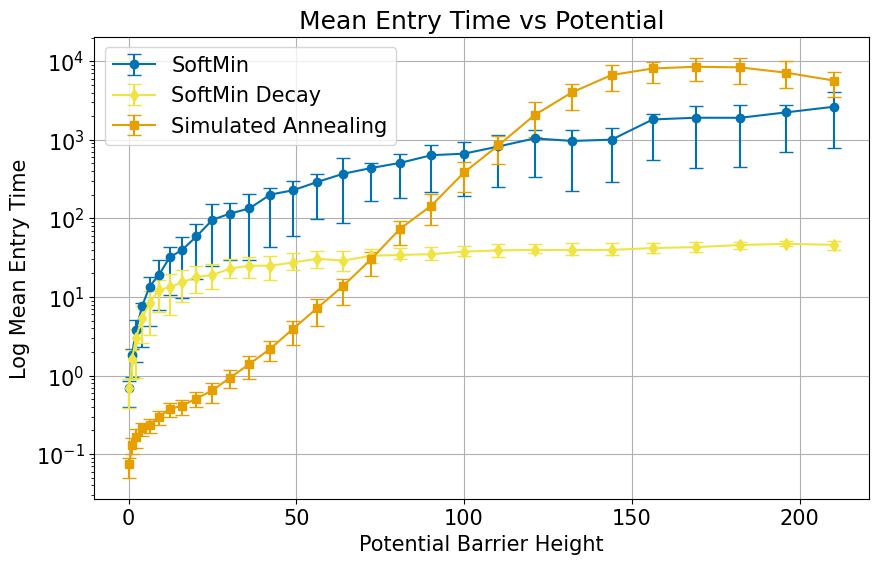

In [18]:
mean_entry_times_softmin, mean_entry_times_softmin_decay, mean_entry_times_simulated_annealing, mean_entry_times_cbo, mean_entry_times_pso = [], [], [], [], []
q1_softmin, q3_softmin = [], []
q1_softmin_decay, q3_softmin_decay = [], []
q1_simulated_annealing, q3_simulated_annealing = [], []
q1_cbo, q3_cbo = [], []
q1_pso, q3_pso = [], []
x_ = []


for A in range(2,31):
    kwargs = unbalanced_quadruple_well_setting(A,-1)
    array_values = np.sort(np.array([np.float_(kwargs['f_vec'](point)) for point in kwargs['critical_points']]))
    x_.append(array_values[4]-array_values[3])
    with open('results/'+'softmin_highermaxsteps_quadruple_well'+f'_{A}.pkl', "rb") as f:
        entry_times_softmin = pkl.load(f)
    with open('results/'+'softmin_decay_highermaxsteps_quadruple_well'+f'_{A}.pkl', "rb") as f:
        entry_times_softmin_decay = pkl.load(f)
    with open('results/'+'sa_highermaxsteps_quadruple_well'+f'_{A}.pkl', "rb") as f:
        entry_times_simulated_annealing = pkl.load(f)
    with open('results/'+'cbo_quadruple_well'+f'_{A}.pkl', "rb") as f:
        entry_times_cbo = pkl.load(f)
    with open('results/'+'pso_quadruple_well'+f'_{A}.pkl', "rb") as f:
        entry_times_pso = pkl.load(f)

    mean_entry_times_softmin.append(np.mean(entry_times_softmin))
    mean_entry_times_softmin_decay.append(np.mean(entry_times_softmin_decay))
    mean_entry_times_simulated_annealing.append(np.mean(entry_times_simulated_annealing))
    mean_entry_times_cbo.append(np.mean(entry_times_cbo))
    mean_entry_times_pso.append(np.mean(entry_times_pso))

    q1_softmin.append(np.percentile(entry_times_softmin, 25))
    q3_softmin.append(np.percentile(entry_times_softmin, 75))
    q1_softmin_decay.append(np.percentile(entry_times_softmin_decay, 25))
    q3_softmin_decay.append(np.percentile(entry_times_softmin_decay, 75))
    q1_simulated_annealing.append(np.percentile(entry_times_simulated_annealing, 25))
    q3_simulated_annealing.append(np.percentile(entry_times_simulated_annealing, 75))
    q1_cbo.append(np.percentile(entry_times_cbo, 25))
    q3_cbo.append(np.percentile(entry_times_cbo, 75))
    q1_pso.append(np.percentile(entry_times_pso, 25))
    q3_pso.append(np.percentile(entry_times_pso, 75))

def get_asymmetric_errorbars(mean, q1, q3):
    lower = np.array(mean) - np.array(q1)
    upper = np.array(q3) - np.array(mean)
    return [np.maximum(0,lower), np.maximum(0,upper)]

err_softmin = get_asymmetric_errorbars(mean_entry_times_softmin, q1_softmin, q3_softmin)
err_softmin_decay = get_asymmetric_errorbars(mean_entry_times_softmin_decay, q1_softmin_decay, q3_softmin_decay)
err_simulated_annealing = get_asymmetric_errorbars(mean_entry_times_simulated_annealing, q1_simulated_annealing, q3_simulated_annealing)
err_cbo = get_asymmetric_errorbars(mean_entry_times_cbo, q1_cbo, q3_cbo)
err_pso = get_asymmetric_errorbars(mean_entry_times_pso, q1_pso, q3_pso)

fig, ax = plt.subplots(figsize=(10, 6))
ax.errorbar(x_, mean_entry_times_softmin, yerr=err_softmin, label='SoftMin',
            marker='o', color='#0072B2', capsize=5, linestyle='-')
ax.errorbar(x_, mean_entry_times_softmin_decay, yerr=err_softmin_decay, label='SoftMin Decay',
            marker='d', color='#F0E442', capsize=5, linestyle='-')
ax.errorbar(x_, mean_entry_times_simulated_annealing, yerr=err_simulated_annealing, label='Simulated Annealing',
            marker='s', color='#E69F00', capsize=5, linestyle='-')
#ax.errorbar(x_, mean_entry_times_cbo, yerr=err_cbo, label='CBO',
#            marker='^', color='#009E73', capsize=5, linestyle='-')
#ax.errorbar(x_, mean_entry_times_pso, yerr=err_pso, label='PSO',
#            marker='D', color='#D55E00', capsize=5, linestyle='-')
ax.set_yscale('log')
ax.set_xlabel('Potential Barrier Height')
ax.set_ylabel('Log Mean Entry Time')
ax.set_title('Mean Entry Time vs Potential')
ax.legend()
ax.grid()
plt.show()

## Hgh Dimensional Ackley Function

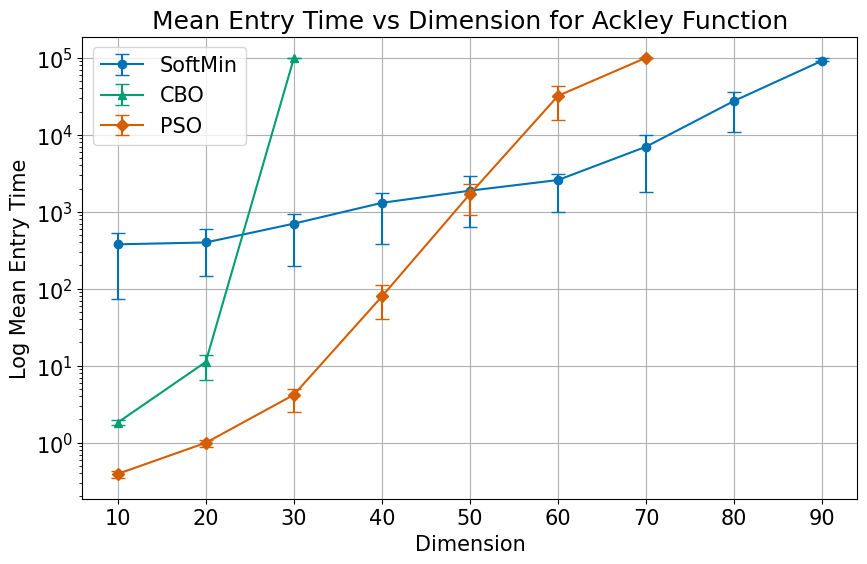

In [40]:
mean_ackley_softmin, mean_ackley_simulated_annealing, mean_ackley_cbo, mean_ackley_pso = [], [], [], []
q1_ackley_softmin, q3_ackley_softmin = [], []
q1_ackley_simulated_annealing, q3_ackley_simulated_annealing = [], []
q1_ackley_cbo, q3_ackley_cbo = [], []
q1_ackley_pso, q3_ackley_pso = [], []
x = []

for dim in range(10, 100, 10):
    x.append(dim)
    with open("results/"+f"SoftMin_decay_ackley_function_dim{dim}.pkl", "rb") as f:
        entry_times_softmin = pkl.load(f)
    with open("results/"+f"SimulatedAnnealing_ackley_function_dim{dim}.pkl", "rb") as f:
        entry_times_simulated_annealing = pkl.load(f)
    with open("results/"+f"CBO_ackley_function_dim{dim}.pkl", "rb") as f:
        entry_times_cbo = pkl.load(f)
    with open("results/"+f"PSO_ackley_function_dim{dim}.pkl", "rb") as f:
        entry_times_pso = pkl.load(f)

    mean_ackley_softmin.append(np.mean(entry_times_softmin))
    mean_ackley_simulated_annealing.append(np.mean(entry_times_simulated_annealing))
    mean_ackley_cbo.append(np.mean(entry_times_cbo))
    mean_ackley_pso.append(np.mean(entry_times_pso))
    q1_ackley_softmin.append(np.percentile(entry_times_softmin, 25))
    q3_ackley_softmin.append(np.percentile(entry_times_softmin, 75))
    q1_ackley_simulated_annealing.append(np.percentile(entry_times_simulated_annealing, 25))
    q3_ackley_simulated_annealing.append(np.percentile(entry_times_simulated_annealing, 75))
    q1_ackley_cbo.append(np.percentile(entry_times_cbo, 25))
    q3_ackley_cbo.append(np.percentile(entry_times_cbo, 75))
    q1_ackley_pso.append(np.percentile(entry_times_pso, 25))
    q3_ackley_pso.append(np.percentile(entry_times_pso, 75))

def get_asymmetric_errorbars(mean, q1, q3):
    lower = np.array(mean) - np.array(q1)
    upper = np.array(q3) - np.array(mean)
    return [np.maximum(lower,0), np.maximum(upper,0)]

err_ackley_softmin = get_asymmetric_errorbars(mean_ackley_softmin, q1_ackley_softmin, q3_ackley_softmin)
err_ackley_simulated_annealing = get_asymmetric_errorbars(mean_ackley_simulated_annealing, q1_ackley_simulated_annealing, q3_ackley_simulated_annealing)
err_ackley_cbo = get_asymmetric_errorbars(mean_ackley_cbo, q1_ackley_cbo, q3_ackley_cbo)
err_ackley_pso = get_asymmetric_errorbars(mean_ackley_pso, q1_ackley_pso, q3_ackley_pso)
fig, ax = plt.subplots(figsize=(10, 6))
# Convert to numpy arrays to enable vectorized masking and avoid list/float TypeError
x = np.asarray(x)
mean_ackley_softmin = np.asarray(mean_ackley_softmin, dtype=float)
mean_ackley_simulated_annealing = np.asarray(mean_ackley_simulated_annealing, dtype=float)
mean_ackley_cbo = np.asarray(mean_ackley_cbo, dtype=float)
mean_ackley_pso = np.asarray(mean_ackley_pso, dtype=float)

err_ackley_softmin = np.asarray(err_ackley_softmin, dtype=float)
err_ackley_simulated_annealing = np.asarray(err_ackley_simulated_annealing, dtype=float)
err_ackley_cbo = np.asarray(err_ackley_cbo, dtype=float)
err_ackley_pso = np.asarray(err_ackley_pso, dtype=float)

ax.errorbar(x[np.where(mean_ackley_softmin < 1e5)],
            mean_ackley_softmin[np.where(mean_ackley_softmin < 1e5)],
            yerr=np.squeeze(err_ackley_softmin[:,np.where(mean_ackley_softmin < 1e5)],axis=1), label='SoftMin',
            marker='o', color='#0072B2', capsize=5, linestyle='-')
#ax.errorbar(x[np.where(mean_ackley_simulated_annealing<1e5)], mean_ackley_simulated_annealing[np.where(mean_ackley_simulated_annealing<1e5)], yerr=err_ackley_simulated_annealing, label='Simulated Annealing',
#            marker='s', color='#E69F00', capsize=5, linestyle='-')
ax.errorbar(x[np.where(mean_ackley_cbo<1e5)], mean_ackley_cbo[np.where(mean_ackley_cbo<1e5)], yerr=np.squeeze(err_ackley_cbo[:,np.where(mean_ackley_cbo<1e5)],axis=1), label='CBO',
            marker='^', color='#009E73', capsize=5, linestyle='-')
ax.errorbar(x[np.where(mean_ackley_pso<1e5)], mean_ackley_pso[np.where(mean_ackley_pso<1e5)], yerr=np.squeeze(err_ackley_pso[:,np.where(mean_ackley_pso<1e5)],axis=1), label='PSO',
            marker='D', color='#D55E00', capsize=5, linestyle='-')
ax.set_yscale('log')
ax.set_xlabel('Dimension')
ax.set_ylabel('Log Mean Entry Time')
ax.set_title(f'Mean Entry Time vs Dimension for Ackley Function')
ax.legend()
ax.grid()
plt.show()